In [1]:
# GAN - Generative Adversarial Network
# Dataset: digits (8x8 handwritten digits) - built into sklearn, no download needed
#
# Needs: pip install tensorflow
#
# How a GAN works - two networks playing a game:
#   Generator     = a forger. Takes random noise, tries to produce a fake image.
#   Discriminator = a detective. Looks at an image, says "real" or "fake".
# They train against each other: the forger gets better at fooling the detective,
# the detective gets better at catching the forger. When it works, the forger ends
# up producing images that look like the real data.
#
# Using 8x8 digits keeps this small enough to train in a minute or two. The exact same
# idea scales to the 28x28 MNIST digits or larger images - just bigger networks
# (usually convolutional) and much longer training.

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)
np.random.seed(42)


C:\Users\syin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\syin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\syin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/

Real images: (1797, 64)


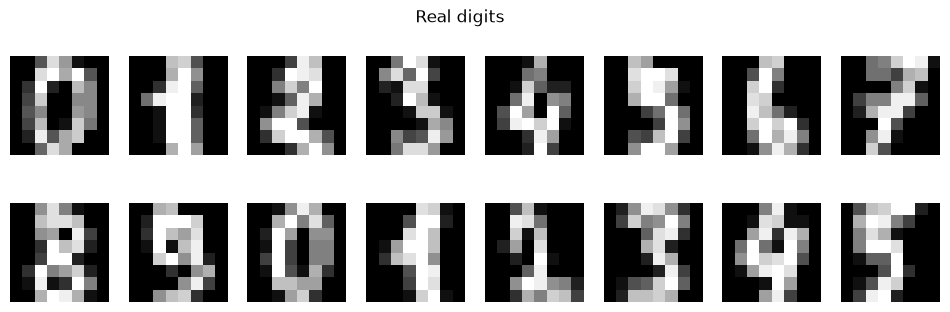

In [2]:
# ---- 1. Load the real images ----
digits = load_digits()
X_real = digits.data.astype("float32")     # shape (1797, 64) - each image flattened to 64 pixels
print("Real images:", X_real.shape)

# ---- 2. Scale pixels to the range -1 to 1 ----
# original range is 0-16. The generator's last layer uses tanh, which outputs -1 to 1,
# so the real data has to live in the same range for the detective to compare fairly.
X_real = (X_real / 16.0) * 2 - 1

# ---- 3. Look at some real digits ----
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_real[i].reshape(8, 8), cmap="gray")
    ax.axis("off")
plt.suptitle("Real digits")
plt.show()

# ---- 4. Settings ----
NOISE_DIM = 32        # length of the random vector the generator starts from
BATCH_SIZE = 64
STEPS = 4000

In [3]:
# ---- 5. The Generator: noise -> fake image ----
generator = keras.Sequential([
    layers.Input(shape=(NOISE_DIM,)),
    layers.Dense(128), layers.LeakyReLU(0.2),
    layers.Dense(256), layers.LeakyReLU(0.2),
    layers.Dense(64, activation="tanh")       # 64 pixels, values in -1..1
], name="generator")

# ---- 6. The Discriminator: image -> probability it is real ----
discriminator = keras.Sequential([
    layers.Input(shape=(64,)),
    layers.Dense(256), layers.LeakyReLU(0.2),
    layers.Dropout(0.3),
    layers.Dense(128), layers.LeakyReLU(0.2),
    layers.Dense(1, activation="sigmoid")     # 1 = real, 0 = fake
], name="discriminator")

# ---- 7. Loss and one optimizer per network ----
# each network gets its own optimizer, and each optimizer only ever updates its OWN
# network's weights. That is what keeps the detective and forger training separately.
bce = keras.losses.BinaryCrossentropy()
g_optimizer = keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
d_optimizer = keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)

real_labels = tf.ones((BATCH_SIZE, 1)) * 0.9    # 0.9 not 1.0: "label smoothing",
fake_labels = tf.zeros((BATCH_SIZE, 1))         # stops the detective getting overconfident

In [4]:
# ---- 8. Training loop ----
d_losses = []
g_losses = []
snapshots = {}                                          # saved fake images at certain steps
fixed_noise = tf.random.normal((16, NOISE_DIM))         # same noise each time, so we can
                                                        # watch the SAME fakes improve
for step in range(1, STEPS + 1):

    # a random batch of real images
    idx = np.random.randint(0, X_real.shape[0], BATCH_SIZE)
    real_batch = tf.constant(X_real[idx])

    # fresh random noise for the forger
    noise = tf.random.normal((BATCH_SIZE, NOISE_DIM))

    # GradientTape records the calculations so we can get gradients afterwards
    with tf.GradientTape() as d_tape, tf.GradientTape() as g_tape:

        fake_batch = generator(noise, training=True)               # forger makes fakes

        real_scores = discriminator(real_batch, training=True)     # detective judges real images
        fake_scores = discriminator(fake_batch, training=True)     # detective judges fakes

        # detective's goal: say "real" for real images and "fake" for fakes
        d_loss = bce(real_labels, real_scores) + bce(fake_labels, fake_scores)

        # forger's goal: make the detective say "real" for its fakes
        g_loss = bce(tf.ones_like(fake_scores), fake_scores)

    # work out how to nudge each network's weights, then apply the nudge
    d_grads = d_tape.gradient(d_loss, discriminator.trainable_variables)
    g_grads = g_tape.gradient(g_loss, generator.trainable_variables)
    
    d_optimizer.apply_gradients(zip(d_grads, discriminator.trainable_variables))
    g_optimizer.apply_gradients(zip(g_grads, generator.trainable_variables))

    d_losses.append(float(d_loss))
    g_losses.append(float(g_loss))

    if step in (1, 500, 1500, STEPS):
        snapshots[step] = generator(fixed_noise, training=False).numpy()

    if step % 500 == 0:
        print(f"Step {step:5d}   Detective loss: {float(d_loss):.3f}   Forger loss: {float(g_loss):.3f}")


Step   500   Detective loss: 1.181   Forger loss: 0.967
Step  1000   Detective loss: 1.153   Forger loss: 1.078
Step  1500   Detective loss: 1.206   Forger loss: 0.970
Step  2000   Detective loss: 1.258   Forger loss: 0.960
Step  2500   Detective loss: 1.163   Forger loss: 1.082
Step  3000   Detective loss: 1.120   Forger loss: 1.141
Step  3500   Detective loss: 1.233   Forger loss: 1.047
Step  4000   Detective loss: 1.188   Forger loss: 1.097


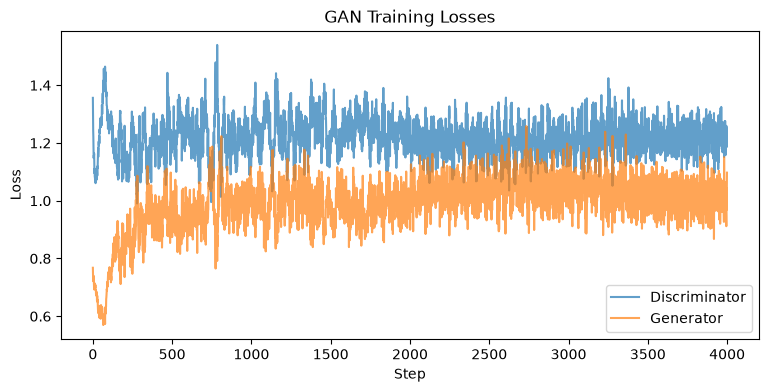

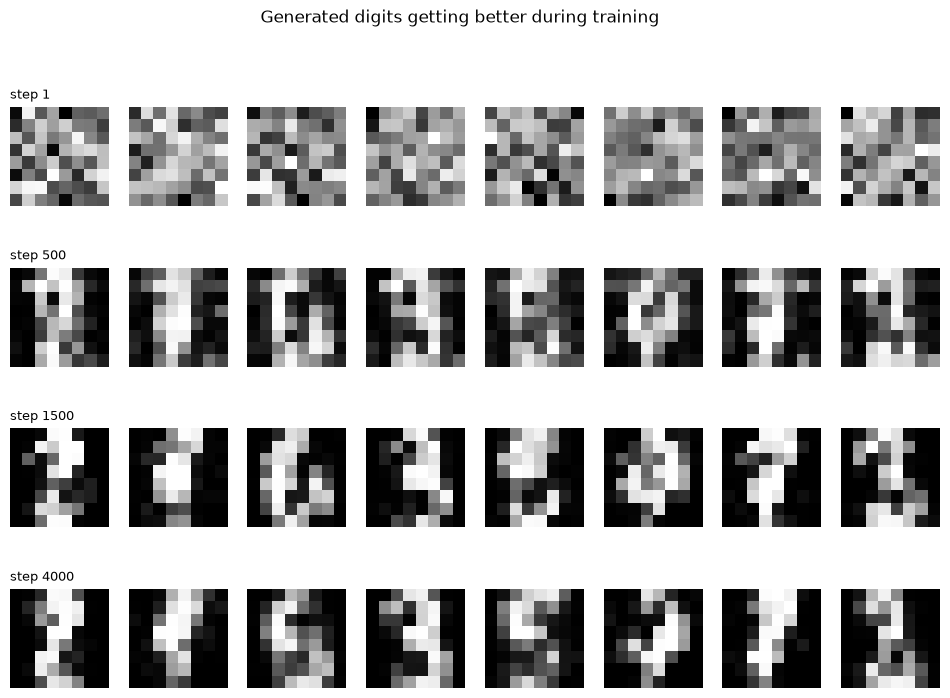

In [5]:
# ---- 9. Loss curves ----
plt.figure(figsize=(9, 4))
plt.plot(d_losses, label="Discriminator", alpha=0.7)
plt.plot(g_losses, label="Generator", alpha=0.7)
plt.title("GAN Training Losses")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.legend()
plt.show()

# unlike normal models, a GAN's loss does NOT steadily fall to zero. The two networks
# keep pushing against each other, so both losses wobble around. What matters is the
# quality of the generated images, not a number going down.

# ---- 10. Watch the fakes improve over training ----
fig, axes = plt.subplots(len(snapshots), 8, figsize=(12, 2 * len(snapshots)))
for row, (step, imgs) in enumerate(snapshots.items()):
    for col in range(8):
        axes[row, col].imshow((imgs[col].reshape(8, 8) + 1) / 2, cmap="gray")
        axes[row, col].axis("off")
    axes[row, 0].set_title(f"step {step}", fontsize=9, loc="left")
plt.suptitle("Generated digits getting better during training")
plt.show()

# step 1: pure static. Later steps: blobs that start to look like strokes and digits.

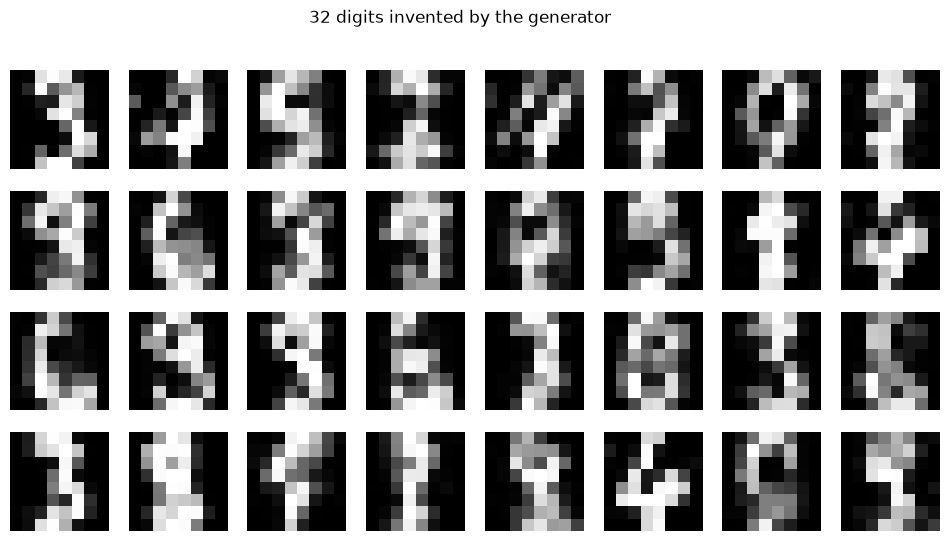

Saved -> gan_digit_generator.keras


In [6]:
# ---- 11. Generate brand-new digits that never existed ----
new_digits = generator(tf.random.normal((32, NOISE_DIM)), training=False).numpy()

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow((new_digits[i].reshape(8, 8) + 1) / 2, cmap="gray")
    ax.axis("off")
plt.suptitle("32 digits invented by the generator")
plt.show()

# ---- 12. Save the generator so you can reuse it without retraining ----
generator.save("gan_digit_generator.keras")
print("Saved -> gan_digit_generator.keras")

# GANs are famously finicky: if one network gets too strong the other can't learn
# ("training collapse"), and the generator may produce only a few kinds of digit
# ("mode collapse"). Tuning learning rates, label smoothing and architecture is
# a big part of making them work in practice.